# Model Selection

This notebook chooses the network for the plane classifier. Four pretrained networks of different sizes are trained on the Spanish images under identical conditions and compared on the African development images, before any African training. The choice follows a rule fixed before the results were seen.

## 0. Setup

In [5]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
from statsmodels.stats.contingency_tables import mcnemar

ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
MODELS = ROOT / "models"
SELECTION = MODELS / "selection"
SELECTION.mkdir(parents=True, exist_ok=True)

from src.training import build_model, fit, get_device, load_model, make_loader, predict

random_seed = 42
np.random.seed(random_seed)

PLANES = ["Fetal abdomen", "Fetal brain", "Fetal femur", "Fetal thorax"]
device = get_device()
print("Device:", device)

Device: mps


## 1. Candidates and decision rule

| Network | Why it is a candidate |
|---|---|
| YOLO11n-cls | Very lightweight classification network from the YOLO family, widely used in practice |
| EfficientNet-B0 | Designed for accuracy per parameter; chosen by Afro-FetalNet |
| MobileNetV3-Large | Designed for phones and low-power devices |
| ResNet18 | Standard baseline; used for the embeddings in Phase 2 |

DenseNet-169, the best network in the original FETAL_PLANES_DB benchmark and the one used by Sendra-Balcells et al., was also considered but excluded: with the shared settings (batch size 32) it exceeded the 8 GB memory of the laptop used for training. This is itself a realistic constraint in low-resource settings, where training and retraining may have to run on similar hardware.

All four start from ImageNet weights and are trained with the same images (Phase 2 pipeline), augmentation, class weights, optimiser (Adam, learning rate 0.0001, weight decay 0.0001), batch size (32), early stopping (validation macro-F1, patience 3, up to 10 epochs) and seed. The YOLO network is trained with the same training loop as the others rather than with its own training program, so that only the network differs.

**Criteria.**

1. Macro-F1 on the 321 African development images, without any African training. This measures how well each network copes with images from new sites, which is the problem the project addresses.
2. Macro-F1 on the Spanish validation images, as a check that each network learned the task.
3. Size (parameters and file size) and inference time per image on a CPU, which matter for deployment in low-resource settings.

**Decision rule (fixed before training).** The network with the highest African macro-F1 is the reference. Every network whose predictions are not significantly different from the reference (McNemar's exact test, p ≥ 0.05) is considered equally good, and among these the network with the fewest parameters is chosen.

The African test images are not used.

## 2. Loading the data

In [6]:
fetal_clean = pd.read_csv(PROCESSED / "fetal_clean.csv")
african_clean = pd.read_csv(PROCESSED / "african_clean.csv")
fetal_images = np.load(PROCESSED / "fetal_processed.npz")["images"]
african_images = np.load(PROCESSED / "african_processed.npz")["images"]

training = fetal_clean[fetal_clean["partition"] == "training"]
validation = fetal_clean[fetal_clean["partition"] == "validation"]
development = african_clean[african_clean["partition"] == "development"]

val_labels = validation["label"].to_numpy()
dev_labels = development["label"].to_numpy()
weights = compute_class_weight("balanced", classes=np.arange(len(PLANES)), y=training["label"])
print("Spanish training:", len(training), "| Spanish validation:", len(validation),
      "| African development:", len(development))

Spanish training: 5220 | Spanish validation: 839 | African development: 321


## 3. Size and inference speed

Inference time is measured on the CPU, one image at a time, as the median of 50 runs after 5 warm-up runs. The times depend on the computer used, so they are compared with each other rather than read as absolute values.

In [7]:
CANDIDATES = ["yolo11n-cls", "efficientnet_b0", "mobilenet_v3_large", "resnet18"]


def cpu_time_ms(model, runs=50, warmup=5):
    model = model.to("cpu").eval()
    x = torch.randn(1, 3, 224, 224)
    times = []
    with torch.no_grad():
        for i in range(warmup + runs):
            start = time.perf_counter()
            model(x)
            if i >= warmup:
                times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))


size = {}
for arch in CANDIDATES:
    model = build_model(num_classes=len(PLANES), arch=arch)
    path = SELECTION / f"{arch}_size_check.pt"
    torch.save(model.state_dict(), path)
    size[arch] = {"parameters (M)": sum(p.numel() for p in model.parameters()) / 1e6,
                  "file size (MB)": path.stat().st_size / 1e6,
                  "CPU time per image (ms)": cpu_time_ms(model)}
    path.unlink()

size = pd.DataFrame(size).T
size.round(2)

,parameters (M),file size (MB),CPU time per image (ms)
yolo11n-cls,1.54,6.27,7.01
efficientnet_b0,4.01,16.35,55.99
mobilenet_v3_large,4.21,17.04,25.65
resnet18,11.18,44.79,21.96


## 4. Training the candidates

Each network is trained on the 5,220 Spanish training images. ResNet18 was already trained with exactly these settings in the model training notebook (section 4), so its saved weights are reused.

In [8]:
def weights_path(arch):
    return MODELS / "spanish_baseline.pt" if arch == "resnet18" else SELECTION / f"{arch}.pt"


for arch in CANDIDATES:
    if weights_path(arch).exists():
        print(f"{arch}: saved weights found, not retrained")
        continue
    print(f"Training {arch}")
    torch.manual_seed(random_seed)
    model = build_model(num_classes=len(PLANES), arch=arch).to(device)
    train_loader = make_loader(fetal_images[training.index], training["label"], train=True, seed=random_seed)
    val_loader = make_loader(fetal_images[validation.index], val_labels)
    loss_fn = torch.nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32).to(device))
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

    start = time.time()
    history = fit(model, train_loader, val_loader, loss_fn, optimizer, device, epochs=10, patience=3)
    history = pd.DataFrame(history).assign(minutes=(time.time() - start) / 60)
    torch.save(model.state_dict(), weights_path(arch))
    history.to_csv(SELECTION / f"{arch}_history.csv", index=False)

yolo11n-cls: saved weights found, not retrained
efficientnet_b0: saved weights found, not retrained
mobilenet_v3_large: saved weights found, not retrained
resnet18: saved weights found, not retrained


## 5. Results

In [9]:
def auc(true, prob):
    return np.mean([roc_auc_score(true == k, prob[:, k]) for k in np.unique(true)])


val_loader = make_loader(fetal_images[validation.index], val_labels)
dev_loader = make_loader(african_images[development.index], dev_labels)

predictions, results = {}, {}
for arch in CANDIDATES:
    model = load_model(weights_path(arch), device, arch=arch)
    _, val_pred, _ = predict(model, val_loader, device)
    _, dev_pred, dev_prob = predict(model, dev_loader, device)
    predictions[arch] = dev_pred
    results[arch] = {
        "Spanish macro-F1": f1_score(val_labels, val_pred, average="macro"),
        "African accuracy": (dev_pred == dev_labels).mean(),
        "African macro-F1": f1_score(dev_labels, dev_pred, average="macro"),
        "African AUC": auc(dev_labels, dev_prob),
    }

results = pd.DataFrame(results).T.join(size)
results.round(3)

YOLO11n-cls summary: 86 layers, 2,812,104 parameters, 2,812,104 gradients, 3.3 GFLOPs


,Spanish macro-F1,African accuracy,African macro-F1,African AUC,parameters (M),file size (MB),CPU time per image (ms)
yolo11n-cls,0.995,0.872,0.862,0.987,1.536,6.271,7.005
efficientnet_b0,0.992,0.941,0.934,0.995,4.013,16.351,55.985
mobilenet_v3_large,0.991,0.875,0.866,0.981,4.207,17.037,25.647
resnet18,0.996,0.953,0.948,0.997,11.179,44.793,21.961


### 5.1 Applying the decision rule

In [10]:
reference = results["African macro-F1"].idxmax()
reference_correct = predictions[reference] == dev_labels

rule = {}
for arch in CANDIDATES:
    correct = predictions[arch] == dev_labels
    only_reference = (reference_correct & ~correct).sum()
    only_this = (~reference_correct & correct).sum()
    p = 1.0 if arch == reference else mcnemar([[0, only_reference], [only_this, 0]], exact=True).pvalue
    rule[arch] = {"African macro-F1": results.loc[arch, "African macro-F1"],
                  "right only with reference": only_reference, "right only with this network": only_this,
                  "McNemar p": p, "equally good": p >= 0.05,
                  "parameters (M)": results.loc[arch, "parameters (M)"]}

rule = pd.DataFrame(rule).T
chosen = rule[rule["equally good"].astype(bool)]["parameters (M)"].astype(float).idxmin()
print("Reference (highest African macro-F1):", reference)
print("Chosen network:", chosen)
rule

Reference (highest African macro-F1): resnet18
Chosen network: efficientnet_b0


,African macro-F1,right only with reference,right only with this network,McNemar p,equally good,parameters (M)
yolo11n-cls,0.862367,32,6,0.000024,False,1.536228
efficientnet_b0,0.934279,14,10,0.541256,True,4.012672
mobilenet_v3_large,0.865627,34,9,0.00017,False,4.207156
resnet18,0.948431,0,0,1.0,True,11.178564


### 5.2 By plane and by country

In [11]:
by_plane = pd.DataFrame({arch: [(predictions[arch][dev_labels == k] == k).mean() for k in range(len(PLANES))]
                         for arch in CANDIDATES}, index=PLANES)
countries = development["Center"].to_numpy()
by_country = pd.DataFrame({arch: {c: (predictions[arch][countries == c] == dev_labels[countries == c]).mean()
                                  for c in sorted(set(countries))} for arch in CANDIDATES})
pd.concat({"Accuracy by plane": by_plane, "Accuracy by country": by_country}).round(3)

yolo11n-cls  efficientnet_b0  \
Accuracy by plane   Fetal abdomen        0.922            0.978   
                    Fetal brain          0.911            0.956   
                    Fetal femur          0.787            0.899   
                    Fetal thorax         0.865            0.923   
Accuracy by country Algeria              0.900            0.983   
                    Egypt                0.779            0.922   
                    Ghana                0.807            0.789   
                    Malawi               0.940            1.000   
                    Uganda               0.950            1.000   

                                   mobilenet_v3_large  resnet18  
Accuracy by plane   Fetal abdomen               0.867     0.922  
                    Fetal brain                 0.900     1.000  
                    Fetal femur                 0.854     0.978  
                    Fetal thorax                0.885     0.885  
Accuracy by country Algeria                     0.933     0.983  
                    Egypt                       0.805     0.948  
                    Ghana                       0.684     0.912  
                    Malawi                      0.955     0.955  
                    Uganda                      1.000     0.967

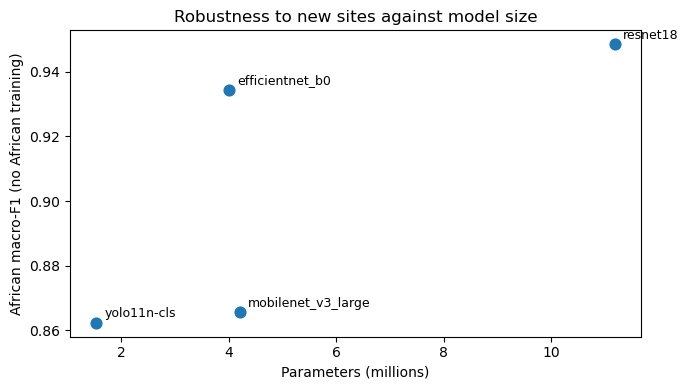

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(results["parameters (M)"], results["African macro-F1"], s=60)
for arch, row in results.iterrows():
    ax.annotate(arch, (row["parameters (M)"], row["African macro-F1"]), textcoords="offset points",
                xytext=(6, 4), fontsize=9)
ax.set_xlabel("Parameters (millions)")
ax.set_ylabel("African macro-F1 (no African training)")
ax.set_title("Robustness to new sites against model size")
plt.tight_layout()
plt.savefig(FIGURES / "fig8_1_model_selection.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Summary

| Network | Parameters (M) | Spanish macro-F1 | African accuracy | African macro-F1 | African AUC | McNemar p vs reference |
|---|---|---|---|---|---|---|
| YOLO11n-cls | 1.5 | 0.995 | 0.872 | 0.862 | 0.987 | < 0.001 |
| EfficientNet-B0 | 4.0 | 0.992 | 0.941 | 0.934 | 0.995 | 0.54 |
| MobileNetV3-Large | 4.2 | 0.991 | 0.875 | 0.866 | 0.981 | < 0.001 |
| ResNet18 | 11.2 | 0.996 | 0.953 | 0.948 | 0.997 | reference |

- **All four networks learned the task.** Spanish validation macro-F1 was between 0.991 and 0.996, so the Spanish data alone could not separate them.
- **They differed on the African images.** ResNet18 had the highest African macro-F1 (0.948) and is the reference. EfficientNet-B0 was close (0.934). YOLO11n-cls and MobileNetV3-Large dropped to about 0.86, a significantly worse result (McNemar p < 0.001): they fitted the Spanish images as well as the others but generalised less well to new sites.
- **Decision.** EfficientNet-B0 is not significantly different from ResNet18 (ResNet18 alone was right on 14 images, EfficientNet-B0 alone on 10; p = 0.54) and has about a third of the parameters (4.0M against 11.2M; 16 MB against 45 MB). Following the rule fixed before training, **EfficientNet-B0 is chosen.**
- **Trade-offs.**
  - EfficientNet-B0 was the slowest network on the CPU (about 56 ms per image, against 22 ms for ResNet18). This is still well under a second per image and was not part of the rule.
  - It was weaker than ResNet18 on Ghana (0.789 against 0.912), Egypt (0.922 against 0.948) and on femur and brain images, and stronger on abdomen, thorax, Malawi and Uganda.
- **Limitations.**
  - Each network was trained once, with one seed.
  - The comparison is before any African training, so the ranking after fine-tuning may differ.
  - DenseNet-169 could not be compared because of the memory limit (section 1).
